# 03 NLP: van omschrijving naar getallen

**Workshop:** LU2 `05_NLP` (opschonen, tokenisatie, stopwoorden, lemmatisatie en stemming, Bag of Words).

De workshop gebruikt Engelse tekst. Onze catalogus is **Nederlands**, dus we gebruiken een Nederlandse stopwoordenlijst en de
Nederlandse Snowball stemmer. Daarna gaan we van Bag of Words naar **TF-IDF**, dat zeldzame en dus onderscheidende woorden zwaarder laat wegen.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from reading_coach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from reading_coach.data_cleaning import load_processed
from reading_coach.text import DUTCH_STOPWORDS, normalize, preprocess, remove_stopwords, stem, tokenize

materials, students, interactions = load_processed()
example = materials.loc[0, "text"]
example

'Het dagboek van Anne Frank. Dagboek van een Joods meisje dat tijdens de Tweede Wereldoorlog onderduikt in Amsterdam. Haar persoonlijke observaties geven een indringend beeld van angst, hoop, groei en het dagelijks leven onder vervolging.. woii onderduik'

## 1. Normaliseren: kleine letters, cijfers en leestekens weg

In [3]:
cleaned = normalize(example)
cleaned

'het dagboek van anne frank dagboek van een joods meisje dat tijdens de tweede wereldoorlog onderduikt in amsterdam haar persoonlijke observaties geven een indringend beeld van angst hoop groei en het dagelijks leven onder vervolging woii onderduik'

## 2. Tokenisatie

In [4]:
tokens = tokenize(example)
print(len(tokens), "tokens")
tokens

37 tokens


['het',
 'dagboek',
 'van',
 'anne',
 'frank',
 'dagboek',
 'van',
 'een',
 'joods',
 'meisje',
 'dat',
 'tijdens',
 'de',
 'tweede',
 'wereldoorlog',
 'onderduikt',
 'in',
 'amsterdam',
 'haar',
 'persoonlijke',
 'observaties',
 'geven',
 'een',
 'indringend',
 'beeld',
 'van',
 'angst',
 'hoop',
 'groei',
 'en',
 'het',
 'dagelijks',
 'leven',
 'onder',
 'vervolging',
 'woii',
 'onderduik']

## 3. Stopwoorden verwijderen
Ik gebruik een algemene Nederlandse stopwoordenlijst (de, het, een). Woorden die in bijna elke omschrijving van déze
catalogus staan, zoals *verhaal* en *boek*, zet ik er niet met de hand bij: de TF-IDF vectorizer laat woorden weg die in meer
dan de helft van de documenten voorkomen (`max_df=0.5`). Zo blijft dat kloppen als de catalogus verandert.

In [5]:
without_stopwords = remove_stopwords(tokens)
print(f"{len(DUTCH_STOPWORDS)} stopwoorden in de lijst")
without_stopwords

124 stopwoorden in de lijst


['dagboek',
 'anne',
 'frank',
 'dagboek',
 'joods',
 'meisje',
 'tweede',
 'wereldoorlog',
 'onderduikt',
 'amsterdam',
 'persoonlijke',
 'observaties',
 'geven',
 'indringend',
 'beeld',
 'angst',
 'hoop',
 'groei',
 'dagelijks',
 'leven',
 'vervolging',
 'woii',
 'onderduik']

## 4. Stemming
NLTK heeft geen Nederlandse WordNet lemmatizer, daarom gebruiken we stemming. Een stam hoeft geen echt woord te zijn: dat is prima, zolang *vriendschap* en *vriendschappen* dezelfde stam krijgen.

In [6]:
from nltk.stem.snowball import SnowballStemmer

stemmer = SnowballStemmer("dutch")
for word in ["vriendschap", "vriendschappen", "oorlogen", "spannende", "spanning", "jongeren", "opgroeien"]:
    print(f"{word:16s} -> {stemmer.stem(word)}")
print()
print(stem(without_stopwords))

vriendschap      -> vriendschap
vriendschappen   -> vriendschapp
oorlogen         -> oorlog
spannende        -> spannend
spanning         -> spanning
jongeren         -> jonger
opgroeien        -> opgroei

['dagboek', 'ann', 'frank', 'dagboek', 'jod', 'meisj', 'twed', 'wereldoorlog', 'onderduikt', 'amsterdam', 'person', 'observaties', 'gev', 'indring', 'beeld', 'angst', 'hop', 'groei', 'dagelijk', 'lev', 'vervolg', 'woii', 'onderduik']


## 5. Bag of Words

Bag of Words: (275, 1059) (1.1% gevuld)


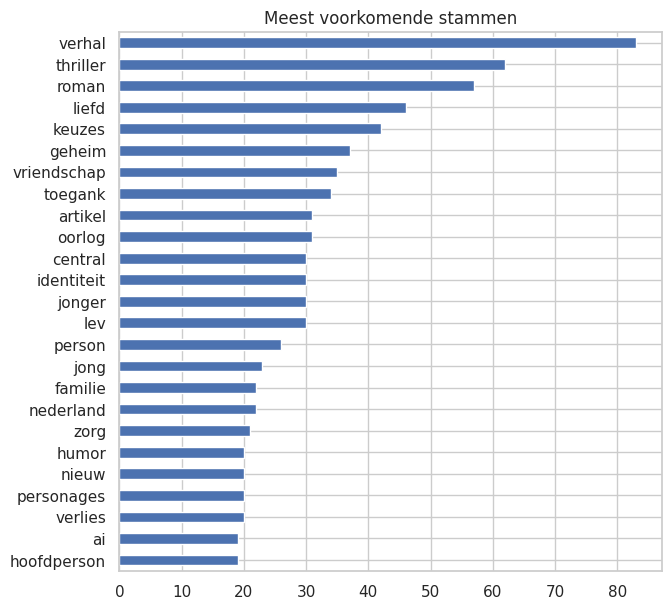

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

documents = materials["text"].fillna("").map(preprocess)
bow = CountVectorizer()
bow_matrix = bow.fit_transform(documents)
print("Bag of Words:", bow_matrix.shape, f"({bow_matrix.nnz / np.prod(bow_matrix.shape):.1%} gevuld)")
word_counts = pd.Series(np.asarray(bow_matrix.sum(axis=0)).ravel(), index=bow.get_feature_names_out()).nlargest(25)
word_counts.plot.barh(figsize=(7, 7), title="Meest voorkomende stammen").invert_yaxis()
plt.show()

## 6. TF-IDF
TF-IDF = hoe vaak een woord in dit document staat, maal hoe zeldzaam het is in alle documenten. Hieronder de woorden die voor een paar materialen het meest kenmerkend zijn.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(documents)
terms = tfidf.get_feature_names_out()
for position in [0, 1, 150, 170]:
    row = tfidf_matrix[position].toarray().ravel()
    top = terms[row.argsort()[::-1][:6]]
    print(f"{materials.loc[position, 'title'][:45]:45s} {', '.join(top)}")

Het dagboek van Anne Frank                    dagboek, vervolg woii, lev vervolg, groei dagelijk, wereldoorlog onderduikt, indring beeld
Blauw Water                                   stalking, spanning, water, gezin bescherm, terwijl, terwijl spanning
CPB: het gaat goed met de Nederlandse economi economie, oplop, staatsschuld oplop, staatsschuld, economie staatsschuld, cpb
We zijn evenwijdig                            tal ontmoet, evenwijd, evenwijd communicatie, communicatie, communicatie tal, we evenwijd


## 7. Interesses van studenten matchen
De student zegt *kunstmatige intelligentie*, de catalogus zegt *AI*. Een student met *technologie* zoekt ook artikelen over
*digitalisering* en *privacy*. Zonder hulp vindt TF-IDF die matches niet, want de woorden komen niet overeen.
Ik breid een interesse daarom op twee manieren uit, allebei zonder lijst in de code:

1. **Synoniemen uit een woordenboek.** De Open Multilingual Wordnet (het Nederlandse deel komt uit Open Dutch WordNet)
   zet woorden met dezelfde betekenis in een *synset*. Twee termen horen bij elkaar als ze een synset delen, of als het
   catalogusthema een nauwere betekenis is (*misdaad*: *cybercrime*). Ook de Engelse woorden van een synset tellen mee,
   want de catalogus gebruikt leenwoorden als *AI*. Ik houd alleen thema's over die echt in de catalogus staan.
2. **Thema's die samen voorkomen.** Thema's die duidelijk vaker voorkomen bij materialen over de interesse dan gemiddeld
   (lift), geleerd uit de catalogus zelf.

De synoniemen worden bij elke training opnieuw bepaald en in MongoDB opgeslagen (collectie `topic_synonyms`), zodat de
Fastify backend dezelfde koppelingen gebruikt.

In [9]:
from reading_coach.content import ContentModel
from reading_coach.hybrid import catalog_themes
from reading_coach.synonyms import as_terms, learn_synonyms
from sklearn.metrics.pairwise import cosine_similarity

interests = ["kunstmatige intelligentie", "maatschappij", "misdaad", "technologie"]
synonyms = as_terms(learn_synonyms(interests, catalog_themes(materials)))
content = ContentModel().fit(materials, synonyms)
for interest in interests:
    print(f"{interest}: synoniemen {synonyms.get(interest, [])}, samen voorkomend {content.expander.related_terms(interest)}")
    for label, text in [("zonder uitbreiding", interest), ("met uitbreiding", content.expander.expand([interest]))]:
        vector = tfidf.transform([preprocess(text)])
        similarity = cosine_similarity(vector, tfidf_matrix).ravel()
        print(f"   {label}: {int((similarity > 0).sum())} materialen met overlap, beste: {materials.loc[similarity.argmax(), 'title']}")

kunstmatige intelligentie: synoniemen ['ai'], samen voorkomend ['ai', 'toezicht', 'rechtspraak', 'rechten van burgers', 'juridische innovatie', 'deepfakes', 'ai-verordening']
   zonder uitbreiding: 0 materialen met overlap, beste: Het dagboek van Anne Frank
   met uitbreiding: 24 materialen met overlap, beste: Gaat AI een rol spelen in de rechtspraak?
maatschappij: synoniemen ['samenleving', 'cultuur'], samen voorkomend ['samenleving', 'cultuur', 'stad', 'religie', 'menselijk gedrag', 'liefde/samenleving', 'macht', 'gender']
   zonder uitbreiding: 1 materialen met overlap, beste: Mensen zonder uitstraling
   met uitbreiding: 56 materialen met overlap, beste: Neem en lees
misdaad: synoniemen ['cybercrime'], samen voorkomend ['cybercrime', 'arbeidsmarkt', 'strafrecht', 'jeugdcriminaliteit', 'fraude', 'discriminatie', 'digitalisering']
   zonder uitbreiding: 3 materialen met overlap, beste: Drop dead famous
   met uitbreiding: 22 materialen met overlap, beste: Vijf vragen over cybercrime


## Conclusie

* De Nederlandse pipeline (normaliseren, tokenizen, stopwoorden, stemmen) staat in `src/reading_coach/text.py` en wordt door
  het model en de API gebruikt.
* TF-IDF met unigrammen en bigrammen is de tekstrepresentatie voor het content based deel (notebook 04).
* Interesses worden uitgebreid met synoniemen uit de wordnet en met thema's die in de catalogus samen voorkomen.
  *Kunstmatige intelligentie* vindt nu de artikelen over *AI*. In notebook 06 is te zien dat dit de top 5 beter maakt.
* De wordnet kent niet alles: samenstellingen als *persoonlijke ontwikkeling* staan er niet in. Daar blijft alleen de
  uitbreiding uit de catalogus over.
* **Mogelijke verbetering:** meertalige *sentence embeddings* begrijpen ook betekenis die niet in de wordnet staat. Dat
  kost wel een groot taalmodel als extra afhankelijkheid.